# IDC409 — House Price Prediction using Machine Learning

**Project type:** Supervised machine learning — regression  
**Dataset:** Kaggle House Prices: Advanced Regression Techniques (Ames Housing)  
**Target:** `SalePrice` (USD)

## Project objectives
1. Use NumPy and pandas for data storage and manipulation.
2. Create and demonstrate a SQLite database with read, write, update and delete operations.
3. Perform exploratory data analysis (EDA).
4. Understand features and demonstrate feature reduction.
5. Train and compare regression models: Linear Regression, Ridge, Lasso, Decision Tree, Random Forest and Gradient Boosting.
6. Evaluate models using MAE, RMSE, R² and MAPE.
7. Save the trained model and provide a function to predict the price of a new house.

> **Important:** The official competition data is not redistributed in this project. Download `train.csv` from Kaggle and place it in the `data/` folder. The notebook checks the data and calculates all results when run; no performance numbers are fabricated.


## 1. Setup and imports

Run the installation command in your terminal if the packages are not installed:

```bash
pip install -r requirements.txt
```


In [1]:
from pathlib import Path
import sqlite3
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

ROOT = Path.cwd()
# If launched from the notebooks folder, move one level up.
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "train.csv"
OUTPUT_DIR = ROOT / "outputs"
MODEL_DIR = ROOT / "models"
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print("Project root:", ROOT.resolve())
print("Dataset path:", DATA_PATH.resolve())


Project root: /Users/imabhay/Documents/Roya Prj IDC/untitled folder
Dataset path: /Users/imabhay/Documents/Roya Prj IDC/untitled folder/data/train.csv


## 2. Load and inspect the dataset

The official Ames competition training file contains the target column `SalePrice`. We first inspect dimensions, data types, missing values and summary statistics. This is also where we verify that the expected target exists.


In [4]:
from pathlib import Path
import pandas as pd

# 1. Locate the project directory
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# 2. Define dataset location
DATA_PATH = ROOT / "data" / "train.csv"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

# 3. Download dataset if it doesn't already exist
DATA_URL = (
    "https://huggingface.co/datasets/michaelmallari/"
    "house-prices-advanced-regression-techniques/"
    "resolve/main/train.csv"
)

if not DATA_PATH.exists():
    print("Dataset not found. Downloading...")
    df_downloaded = pd.read_csv(DATA_URL)
    df_downloaded.to_csv(DATA_PATH, index=False)
    print("Download completed!")

# 4. Load and validate dataset
df_raw = pd.read_csv(DATA_PATH)

if "SalePrice" not in df_raw.columns:
    raise ValueError("Expected target column 'SalePrice' was not found.")

# 5. Display dataset information
print(f"Dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print("Dataset location:", DATA_PATH)

display(df_raw.head())
df_raw.info()
display(df_raw.describe(include="all").T)

Dataset shape: 1,460 rows × 81 columns
Dataset location: /Users/imabhay/Documents/Roya Prj IDC/untitled folder/untitled folder/data/train.csv


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.0,NaN,NaN,NaN,730.5,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,NaN,NaN,NaN,56.89726,42.300571,20.0,20.0,50.0,70.0,190.0
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.0,NaN,NaN,NaN,70.049958,24.284752,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,NaN,NaN,NaN,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.5,215245.0
...,...,...,...,...,...,...,...,...,...,...,...
MoSold,1460.0,NaN,NaN,NaN,6.321918,2.703626,1.0,5.0,6.0,8.0,12.0
YrSold,1460.0,NaN,NaN,NaN,2007.815753,1.328095,2006.0,2007.0,2008.0,2009.0,2010.0
SaleType,1460,9,WD,1267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SaleCondition,1460,6,Normal,1198,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1 Missing-value and duplicate audit

We quantify missingness before cleaning. In this dataset, missing values can carry meaning (for example, no garage or basement), so we use a pipeline with explicit imputers rather than deleting large numbers of rows.


In [5]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values("missing_percent", ascending=False)
print("Duplicate rows:", df_raw.duplicated().sum())
display(missing.head(25))


Duplicate rows: 0


,missing_count,missing_percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


## 3. Data cleaning and SQLite database

We remove duplicate records, separate the target from the input features, and use median imputation for numeric columns and most-frequent imputation for categorical columns inside the machine-learning pipeline. This prevents information from the test set leaking into preprocessing.

The database demonstration creates a SQLite table, reads records, inserts a summary record, updates it and deletes the demonstration record.


In [7]:
import sqlite3
from pathlib import Path

# Ensure output directory exists
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Database location
DB_PATH = OUTPUT_DIR / "house_prices.db"

# Save cleaned dataset into SQLite
with sqlite3.connect(DB_PATH) as conn:

    df.to_sql("houses", conn, if_exists="replace", index=False)

    print("READ — first five database rows:")
    display(pd.read_sql_query(
        "SELECT Id, OverallQual, GrLivArea, SalePrice FROM houses LIMIT 5",
        conn
    ))

    print("\nUPDATE — example database update:")
    conn.execute(
        "UPDATE houses SET SalePrice = SalePrice WHERE Id = 1"
    )

    print("DELETE — example database delete:")
    conn.execute(
        "DELETE FROM houses WHERE Id = -1"
    )

print("\nDatabase successfully created at:", DB_PATH)

READ — first five database rows:


,Id,OverallQual,GrLivArea,SalePrice
0,1,7,1710,208500
1,2,6,1262,181500
2,3,7,1786,223500
3,4,7,1717,140000
4,5,8,2198,250000



UPDATE — example database update:
DELETE — example database delete:

Database successfully created at: /Users/imabhay/Documents/Roya Prj IDC/untitled folder/untitled folder/outputs/house_prices.db


## 4. Exploratory Data Analysis (EDA)

We examine the target distribution, relationship between living area and price, overall quality and price, neighbourhood-level price differences, and numeric correlations. The plots are saved in `outputs/figures/` for the final report.


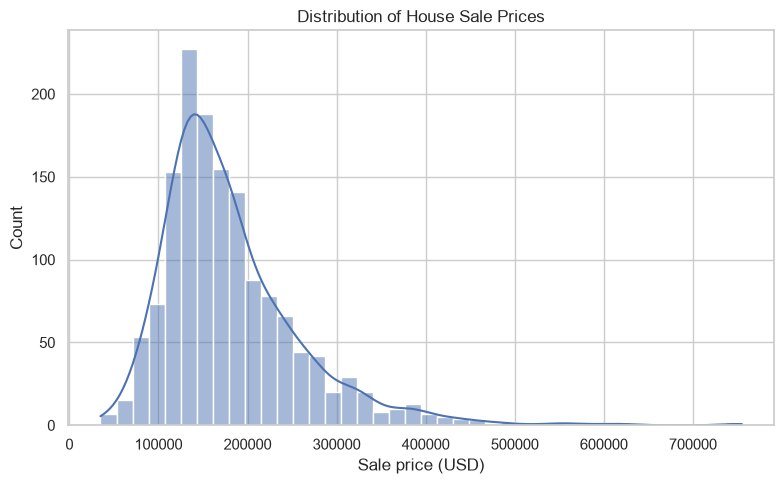

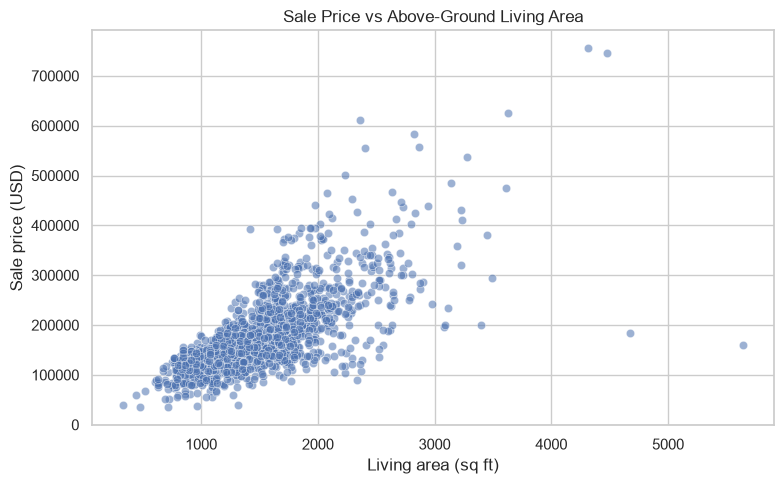

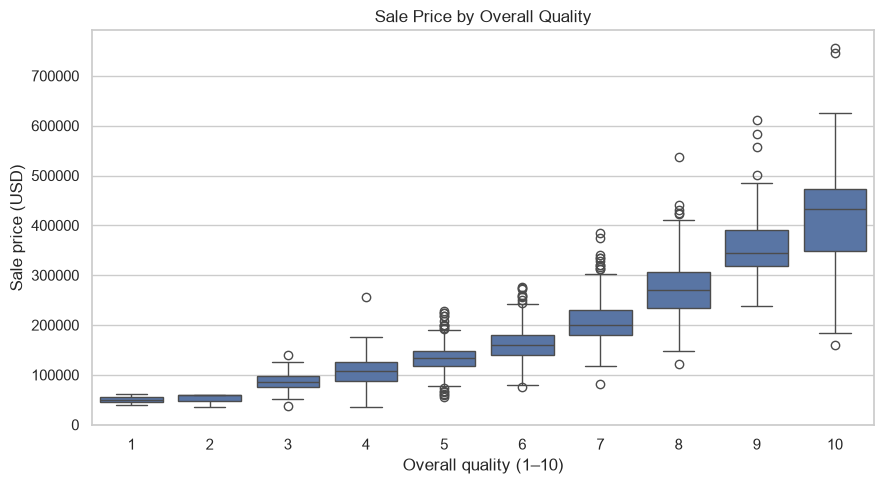

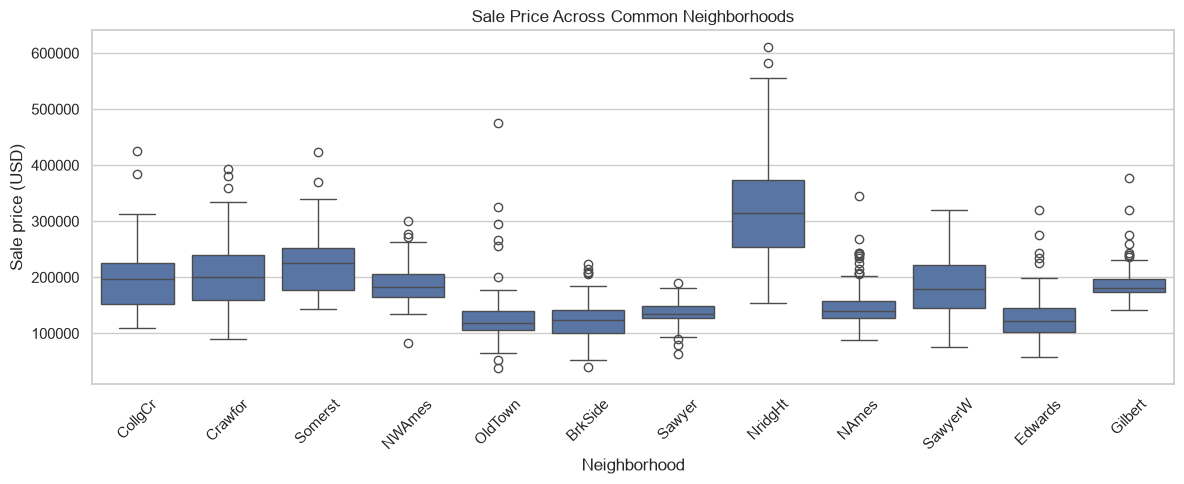

In [8]:
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

def save_show(fig, filename):
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["SalePrice"], bins=40, kde=True, ax=ax)
ax.set(title="Distribution of House Sale Prices", xlabel="Sale price (USD)")
save_show(fig, "01_sale_price_distribution.png")

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=.55, ax=ax)
ax.set(title="Sale Price vs Above-Ground Living Area", xlabel="Living area (sq ft)", ylabel="Sale price (USD)")
save_show(fig, "02_price_vs_living_area.png")

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=ax)
ax.set(title="Sale Price by Overall Quality", xlabel="Overall quality (1–10)", ylabel="Sale price (USD)")
save_show(fig, "03_price_by_quality.png")

fig, ax = plt.subplots(figsize=(12, 5))
top_neighborhoods = df["Neighborhood"].value_counts().head(12).index
sns.boxplot(data=df[df["Neighborhood"].isin(top_neighborhoods)],
            x="Neighborhood", y="SalePrice", ax=ax)
ax.tick_params(axis="x", rotation=45)
ax.set(title="Sale Price Across Common Neighborhoods", ylabel="Sale price (USD)")
save_show(fig, "04_price_by_neighborhood.png")


,correlation_with_SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


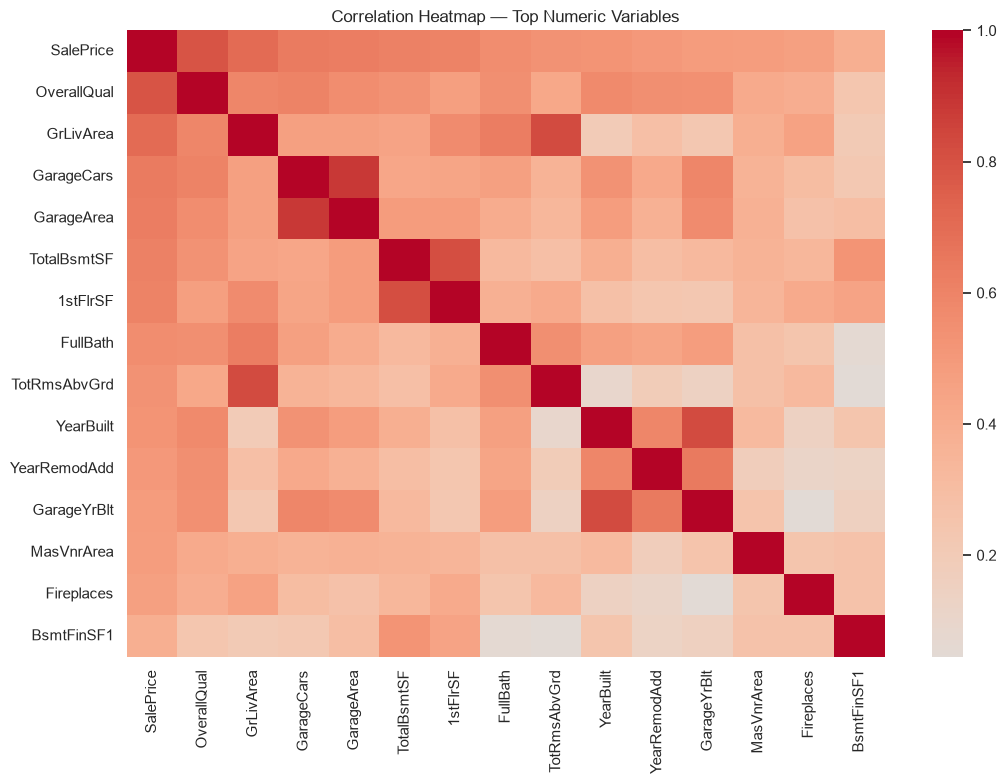

In [9]:
numeric_for_corr = df.select_dtypes(include=np.number)
corr = numeric_for_corr.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)
display(corr.head(15).to_frame("correlation_with_SalePrice"))

fig, ax = plt.subplots(figsize=(11, 8))
top_corr_cols = corr.abs().sort_values(ascending=False).head(15).index
sns.heatmap(df[top_corr_cols].corr(numeric_only=True), cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap — Top Numeric Variables")
save_show(fig, "05_correlation_heatmap.png")


### EDA interpretation

Use the charts and tables above to write observations in your submission. Typical questions to answer:
- Is the target price distribution symmetric or skewed?
- Does living area appear related to sale price?
- How does overall quality affect price?
- Do neighbourhoods show different price distributions?
- Which numeric variables have the strongest correlation with the target?

Do not assume correlation proves causation.


## 5. Feature preparation and feature reduction

`Id` is an identifier and is excluded from modelling. We retain the remaining columns and let the preprocessing pipeline:
- impute numeric missing values with the median;
- standardize numeric variables for linear models;
- impute categorical values with the most frequent category;
- one-hot encode categorical variables, ignoring unseen categories at prediction time.

We use permutation importance on the held-out test set to rank features, then compare a reduced model using the highest-ranked original features with the full model.


In [10]:
TARGET = "SalePrice"
DROP_COLS = ["Id", TARGET]
X = df.drop(columns=DROP_COLS, errors="ignore")
y = df[TARGET].astype(float)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))


Numeric features: 36
Categorical features: 43
Total input features: 79
Training rows: 1168 | Test rows: 292


In [12]:
def make_preprocessor(scale_numeric=False):
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if scale_numeric else "passthrough")
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ])

def make_model(estimator, scale_numeric=False):
    return Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric)),
        ("regressor", estimator)
    ])



## 6. Train regression models

We compare a mean baseline with Linear Regression, Ridge, Lasso, Decision Tree, Random Forest and Gradient Boosting. Hyperparameter tuning is performed using cross-validation on training data only. The test set is reserved for final evaluation.


In [13]:
models = {
    "Linear Regression": make_model(LinearRegression(), True),
    "Ridge Regression": make_model(Ridge(), True),
    "Lasso Regression": make_model(Lasso(max_iter=20000), True),
    "Decision Tree": make_model(DecisionTreeRegressor(random_state=SEED)),
    "Random Forest": make_model(RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=SEED, n_jobs=-1
    )),
    "Gradient Boosting": make_model(GradientBoostingRegressor(random_state=SEED))
}

param_distributions = {
    "Ridge Regression": {"regressor__alpha": [0.1, 1, 10, 50, 100]},
    "Lasso Regression": {"regressor__alpha": [0.0001, 0.001, 0.01, 0.1, 1]},
    "Decision Tree": {"regressor__max_depth": [None, 5, 10, 20],
                      "regressor__min_samples_leaf": [1, 2, 5, 10]},
    "Random Forest": {"regressor__max_depth": [None, 10, 20],
                      "regressor__min_samples_leaf": [1, 2, 4],
                      "regressor__max_features": [0.5, 0.8, 1.0]},
    "Gradient Boosting": {"regressor__n_estimators": [100, 200, 300],
                          "regressor__learning_rate": [0.03, 0.05, 0.1],
                          "regressor__max_depth": [2, 3, 4]}
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
fitted_models = {}
cv_scores = {}

for name, pipeline in models.items():
    if name in param_distributions:
        search = RandomizedSearchCV(
            pipeline, param_distributions[name], n_iter=8,
            scoring="neg_mean_absolute_error", cv=cv,
            random_state=SEED, n_jobs=-1, verbose=0
        )
        search.fit(X_train, y_train)
        fitted_models[name] = search.best_estimator_
        cv_scores[name] = -search.best_score_
        print(name, "best params:", search.best_params_)
    else:
        pipeline.fit(X_train, y_train)
        fitted_models[name] = pipeline
        from sklearn.model_selection import cross_val_score
        scores = cross_val_score(pipeline, X_train, y_train, cv=cv,
                                 scoring="neg_mean_absolute_error", n_jobs=-1)
        cv_scores[name] = -scores.mean()
    print(f"{name}: CV MAE = ${cv_scores[name]:,.2f}")


Linear Regression: CV MAE = $19,621.98
Ridge Regression best params: {'regressor__alpha': 10}
Ridge Regression: CV MAE = $18,001.48
Lasso Regression best params: {'regressor__alpha': 1}
Lasso Regression: CV MAE = $19,302.71
Decision Tree best params: {'regressor__min_samples_leaf': 10, 'regressor__max_depth': 10}
Decision Tree: CV MAE = $24,711.22
Random Forest best params: {'regressor__min_samples_leaf': 1, 'regressor__max_features': 0.5, 'regressor__max_depth': None}
Random Forest: CV MAE = $17,682.07
Gradient Boosting best params: {'regressor__n_estimators': 300, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.05}
Gradient Boosting: CV MAE = $15,944.78


## 7. Model evaluation

We report:
- **MAE:** average absolute prediction error in dollars.
- **RMSE:** penalizes larger errors more strongly.
- **R²:** proportion of target variance explained by the model.
- **MAPE:** average absolute percentage error.

The mean baseline is included so that the models are compared against a simple reference.


In [14]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    nonzero = np.abs(y_true) > 1e-9
    return {
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100
    }

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
all_results = {"Mean Baseline": regression_metrics(y_test, baseline.predict(X_test))}
for name, model in fitted_models.items():
    all_results[name] = regression_metrics(y_test, model.predict(X_test))

results_df = pd.DataFrame(all_results).T
results_df["CV_MAE ($)"] = pd.Series(cv_scores)
display(results_df.sort_values("MAE ($)"))
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv")

best_name = results_df.drop(index="Mean Baseline")["CV_MAE ($)"].idxmin()
best_model = fitted_models[best_name]
print("Best model selected using training cross-validation MAE:", best_name)


,MAE ($),RMSE ($),R2,MAPE (%),CV_MAE ($)
Gradient Boosting,15775.005348,26121.512682,0.911042,9.501340,15944.783902
Random Forest,16930.038438,28513.003649,0.894008,10.450206,17682.065929
Lasso Regression,17921.055465,28240.700496,0.896023,11.084937,19302.707857
Linear Regression,18287.775095,29473.911893,0.886744,11.286358,19621.981805
Ridge Regression,19040.561546,30646.304221,0.877555,11.674112,18001.482651
Decision Tree,24325.458446,39443.248768,0.797170,14.331925,24711.215464
Mean Baseline,62575.926452,87619.034506,-0.000882,41.355831,NaN


Best model selected using training cross-validation MAE: Gradient Boosting


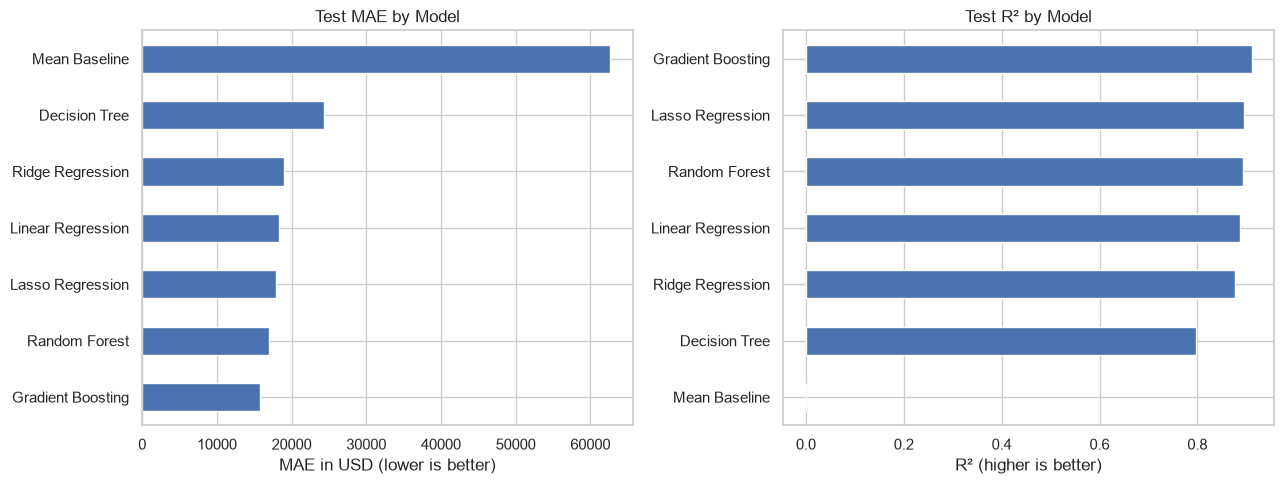

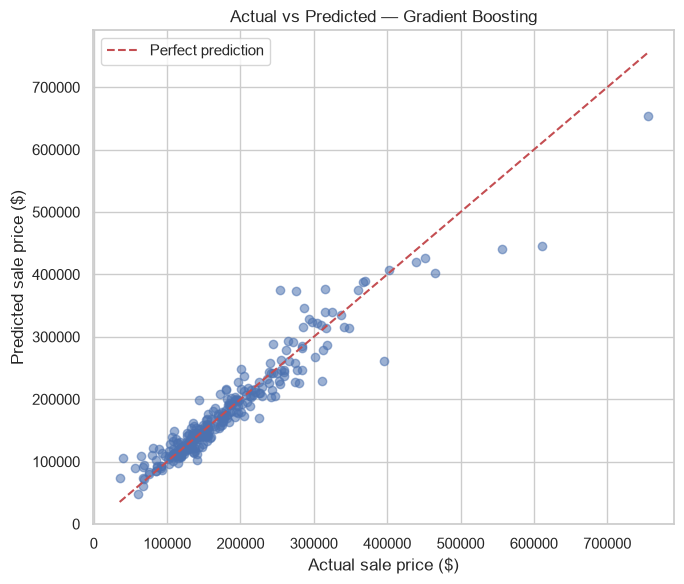

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
results_df["MAE ($)"].sort_values().plot(kind="barh", ax=axes[0], title="Test MAE by Model")
results_df["R2"].sort_values().plot(kind="barh", ax=axes[1], title="Test R² by Model")
axes[0].set_xlabel("MAE in USD (lower is better)")
axes[1].set_xlabel("R² (higher is better)")
save_show(fig, "06_model_comparison.png")

y_pred = best_model.predict(X_test)
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred, alpha=.55)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, "r--", label="Perfect prediction")
ax.set(xlabel="Actual sale price ($)", ylabel="Predicted sale price ($)",
       title=f"Actual vs Predicted — {best_name}")
ax.legend()
save_show(fig, "07_actual_vs_predicted.png")


## 8. Feature importance and reduced-feature experiment

Permutation importance estimates how much the test-set MAE worsens when a feature is shuffled. For categorical variables, the entire original feature is permuted through the pipeline, rather than trying to interpret individual one-hot columns.

We then select the top 15 original features and compare a reduced-feature model with the full-feature model. The selected feature count can be adjusted.


,feature,importance_mean,importance_std
16,OverallQual,16548.870890,955.831919
45,GrLivArea,11837.747470,569.162928
37,TotalBsmtSF,3253.428121,410.833772
60,GarageCars,1980.345861,119.187540
17,OverallCond,1326.312975,242.719007
3,LotArea,1279.730783,75.968557
33,BsmtFinSF1,1237.820146,265.102701
18,YearBuilt,1175.459618,127.577509
43,2ndFlrSF,884.381116,41.414479
19,YearRemodAdd,710.984618,271.164061


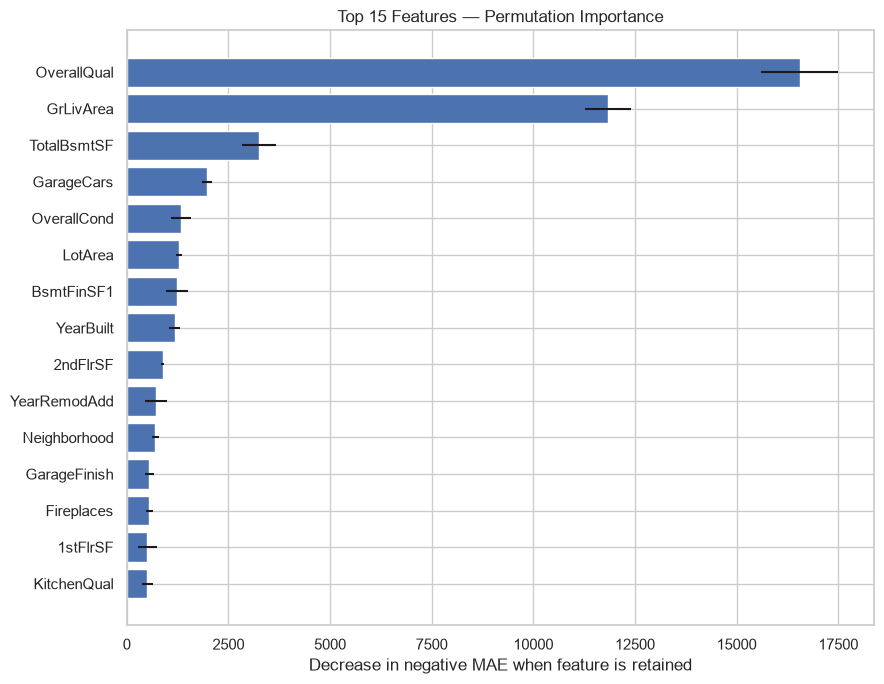

,MAE ($),RMSE ($),R2,MAPE (%)
Full feature set,15775.005348,26121.512682,0.911042,9.501340
Reduced (15 features),15786.715258,25364.084469,0.916127,9.415873


In [16]:
perm = permutation_importance(
    best_model, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=5, random_state=SEED, n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance.head(20))

fig, ax = plt.subplots(figsize=(9, 7))
top_imp = importance.head(15).sort_values("importance_mean")
ax.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
ax.set(title="Top 15 Features — Permutation Importance",
       xlabel="Decrease in negative MAE when feature is retained")
save_show(fig, "08_feature_importance.png")

N_TOP_FEATURES = min(15, X.shape[1])
selected_features = importance.head(N_TOP_FEATURES)["feature"].tolist()
X_train_reduced = X_train[selected_features]
X_test_reduced = X_test[selected_features]

num_reduced = [c for c in selected_features if c in numeric_features]
cat_reduced = [c for c in selected_features if c in categorical_features]

def make_reduced_model():
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("numeric", num_pipe, num_reduced),
                              ("categorical", cat_pipe, cat_reduced)])
    return Pipeline([("preprocessor", prep),
                     ("regressor", clone(best_model.named_steps["regressor"]))])

reduced_model = make_reduced_model()
reduced_model.fit(X_train_reduced, y_train)
reduced_metrics = regression_metrics(y_test, reduced_model.predict(X_test_reduced))
feature_comparison = pd.DataFrame({
    "Full feature set": regression_metrics(y_test, best_model.predict(X_test)),
    f"Reduced ({N_TOP_FEATURES} features)": reduced_metrics
}).T
display(feature_comparison)
feature_comparison.to_csv(OUTPUT_DIR / "feature_reduction_comparison.csv")


## 9. Residual analysis

Residuals are the differences between actual and predicted prices. We inspect their distribution and relationship with predicted values to identify systematic over- or under-prediction.


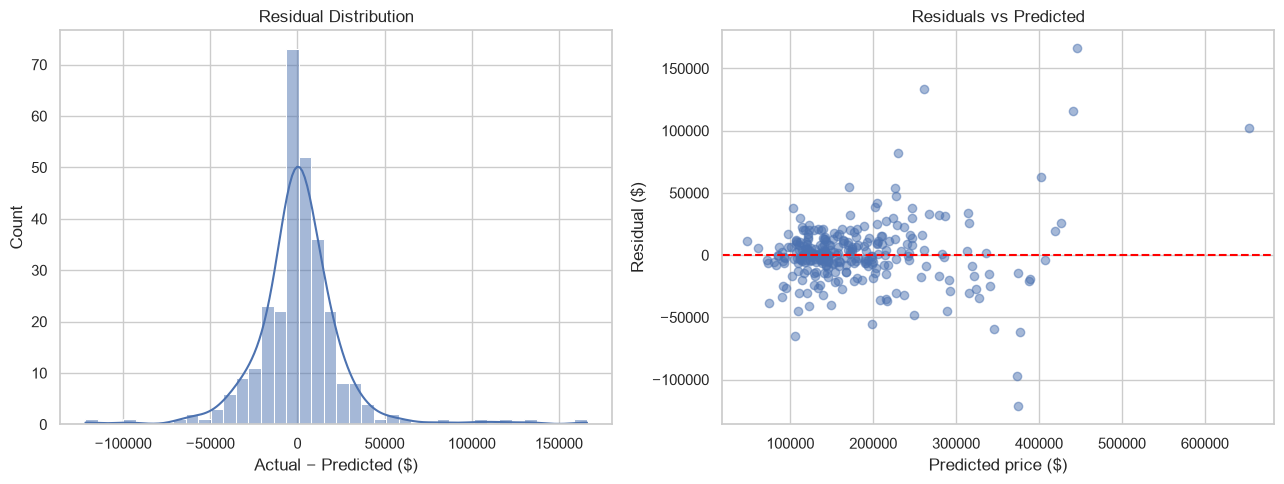

In [17]:
residuals = y_test.to_numpy() - y_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(residuals, bins=40, kde=True, ax=axes[0])
axes[0].set(title="Residual Distribution", xlabel="Actual − Predicted ($)")
axes[1].scatter(y_pred, residuals, alpha=.5)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(title="Residuals vs Predicted", xlabel="Predicted price ($)", ylabel="Residual ($)")
save_show(fig, "09_residual_analysis.png")


## 10. Save the trained model and predict a new house

The complete preprocessing and regression pipeline is saved as one model object. That means missing-value imputation and categorical encoding are applied consistently at prediction time.


In [18]:
MODEL_PATH = MODEL_DIR / "best_house_price_model.joblib"
joblib.dump({
    "model": best_model,
    "model_name": best_name,
    "feature_columns": X.columns.tolist(),
    "target": TARGET
}, MODEL_PATH)
print("Saved model:", MODEL_PATH)


Saved model: /Users/imabhay/Documents/Roya Prj IDC/untitled folder/models/best_house_price_model.joblib


In [19]:
def predict_house_price(property_details, model_path=MODEL_PATH):
    """Predict sale price in USD from a dictionary of house attributes.

    Missing input fields are filled with NaN and handled by the saved pipeline.
    The caller must provide values using the original Ames dataset column names.
    """
    bundle = joblib.load(model_path)
    row = pd.DataFrame([property_details])
    expected = bundle["feature_columns"]
    for col in expected:
        if col not in row.columns:
            row[col] = np.nan
    row = row[expected]
    prediction = float(bundle["model"].predict(row)[0])
    return {"predicted_sale_price_usd": round(prediction, 2),
            "model": bundle["model_name"]}

# Example: illustrative inputs; missing fields are imputed by the trained pipeline.
example_house = {
    "OverallQual": 7,
    "GrLivArea": 1800,
    "GarageCars": 2,
    "TotalBsmtSF": 900,
    "FullBath": 2,
    "YearBuilt": 2005,
    "Neighborhood": "CollgCr",
    "KitchenQual": "Gd",
    "GarageArea": 500
}
predict_house_price(example_house)


{'predicted_sale_price_usd': 188352.39, 'model': 'Gradient Boosting'}

## 11. Final conclusion

After running the notebook, write a short conclusion using the actual generated metrics:

1. State the number of records and features used.
2. Summarize important data-quality observations and missing-value treatment.
3. Mention the main EDA relationships supported by the plots.
4. Name the best model based on cross-validation MAE and report its held-out MAE, RMSE and R².
5. Explain which features ranked highest in permutation importance.
6. Compare full and reduced feature-set performance.
7. State limitations: this is a historical Ames, Iowa dataset and its predictions should not be interpreted as current Indian property valuations.

## 12. Reproducibility and GitHub

The notebook writes the SQLite database, model comparison tables, charts and serialized model to the `outputs/` and `models/` directories. See the repository `README.md` for setup and execution instructions.
